# SINDy from scratch — discovering the vessel ODE

We recover the surge--sway--yaw dynamics of the course vessel benchmark *from data* using
**SINDy** (sparse regression over a candidate library) with sequentially-thresholded least
squares (STLSQ). Six facets:

1. **coefficient recovery** --- the discovered numbers match the benchmark,
2. the **sparsity knob** --- a threshold sweep that finds the right number of terms,
3. **noise robustness** --- ensemble-SINDy gives inclusion probabilities and error bars,
4. the **weak form** --- no derivatives of the data; a noise sweep against finite differences,
5. **validation** --- integrate the discovered equations on an *unseen* maneuver,
6. **closing the loop** --- run SINDy on a learned correction term to recover a missing term as
   an equation,
7. **STLSQ step by step**, 8. **the weak form pictured**, 9. **the derivative error budget** --- the
   illustrations used in the lecture.

The vessel: $\mathbf{M}\dot{\boldsymbol\nu}+\mathbf{C}(\boldsymbol\nu)\boldsymbol\nu+\mathbf{D}(\boldsymbol\nu)\boldsymbol\nu=\boldsymbol\tau$,
i.e. $55\dot u=\tau_1+80vr-10u-5|u|u$, $80\dot v=\tau_2-55ur-40v-40|v|v$, $30\dot r=\tau_3-25uv-15r-10|r|r$
(`pyutils/benchmarks/vessel.py`).

Library per equation: $\{1,u,v,r,|u|u,|v|v,|r|r,uv,ur,vr,\tau_1,\tau_2,\tau_3\}$.

The prose narrates the **default** run. Change the values below and *Run All*; every figure follows.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
T_ID, DT = 80.0, 0.02            # identification maneuver length and sampling step [s]
LAM_CLEAN = 0.02                 # STLSQ threshold (normalized coefficients), clean derivatives
ENS_NOISE, ENS_B, ENS_LAM = 0.03, 80, 0.04   # ensemble-SINDy: noise (fraction of channel std), resamples, threshold
N_WIN, WIN_LEN, WIN_Q = 60, 400, 4           # weak form: windows, window length (samples), bump exponent
LAM_WEAK = 1.0                   # common threshold of the weak-form vs finite-difference sweep
NOISE_LEVELS, N_SEEDS = [0, 0.5, 1, 2, 5, 10], 5   # sweep noise levels [% of channel std] and seeds
VAL_TAU1, VAL_TAU3, VAL_T = 120.0, 30.0, 40.0      # validation turning circle
LAM_LOOP = 0.05                  # threshold for the learned-correction regression
STEP_NOISE, STEP_LAM = 0.02, 0.5 # STLSQ step-by-step illustration
# --------------------------------------------------------------------------
DEFAULTS = dict(T_ID=80.0, DT=0.02, LAM_CLEAN=0.02, ENS_NOISE=0.03, ENS_B=80, ENS_LAM=0.04, N_WIN=60, WIN_LEN=400,
                WIN_Q=4, LAM_WEAK=1.0, NOISE_LEVELS=[0, 0.5, 1, 2, 5, 10], N_SEEDS=5, VAL_TAU1=120.0, VAL_TAU3=30.0,
                VAL_T=40.0, LAM_LOOP=0.05, STEP_NOISE=0.02, STEP_LAM=0.5)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np
import matplotlib.pyplot as plt
from pyutils import set_plot_style; set_plot_style()
from pyutils.benchmarks import vessel
np.random.seed(0)

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
from pyutils import save_dual, fg

p = vessel.VesselParams()
def tau_fn(t, z): return np.array([150 + 100*np.sin(0.3*t), 90*np.sin(0.5*t + 1), 60*np.sin(0.7*t)])
dt = DT; t, Z = vessel.simulate(tau_fn, t_end=T_ID, dt=dt, p=p)
nu = Z[:, 3:]; tau = np.array([tau_fn(tk, zk) for tk, zk in zip(t, Z)])
nudot = np.array([vessel.state_derivative(z, tau_fn(tk, z), p)[3:] for tk, z in zip(t, Z)])

def library(nu, tau):
    u, v, r = nu[:, 0], nu[:, 1], nu[:, 2]
    cols = {'1': np.ones_like(u), 'u': u, 'v': v, 'r': r, '|u|u': np.abs(u)*u,
            '|v|v': np.abs(v)*v, '|r|r': np.abs(r)*r, 'uv': u*v, 'ur': u*r, 'vr': v*r,
            'tau1': tau[:, 0], 'tau2': tau[:, 1], 'tau3': tau[:, 2]}
    names = list(cols); return np.stack([cols[n] for n in names], 1), names

def stlsq(Theta, dXdt, lam, n_iter=20):
    norm = np.linalg.norm(Theta, axis=0) + 1e-12; Tn = Theta/norm
    Xi = np.linalg.lstsq(Tn, dXdt, rcond=None)[0]
    for _ in range(n_iter):
        small = np.abs(Xi) < lam; Xi[small] = 0
        for j in range(dXdt.shape[1]):
            big = ~small[:, j]
            if big.any():
                Xi[big, j] = np.linalg.lstsq(Tn[:, big], dXdt[:, j], rcond=None)[0]
    return Xi / norm[:, None]

Theta, names = library(nu, tau)
Xi = stlsq(Theta, nudot, lam=LAM_CLEAN)
print('library terms:', names)

library terms: ['1', 'u', 'v', 'r', '|u|u', '|v|v', '|r|r', 'uv', 'ur', 'vr', 'tau1', 'tau2', 'tau3']


## 1. Coefficient recovery (clean derivatives)

With analytic derivatives the recovered coefficients match the benchmark
$\mathbf{M}=\mathrm{diag}(55,80,30)$ term for term:
$\dot u=(\tau_1+80vr-10u-5|u|u)/55$, $\dot v=(\tau_2-55ur-40v-40|v|v)/80$,
$\dot r=(\tau_3-25uv-15r-10|r|r)/30$.

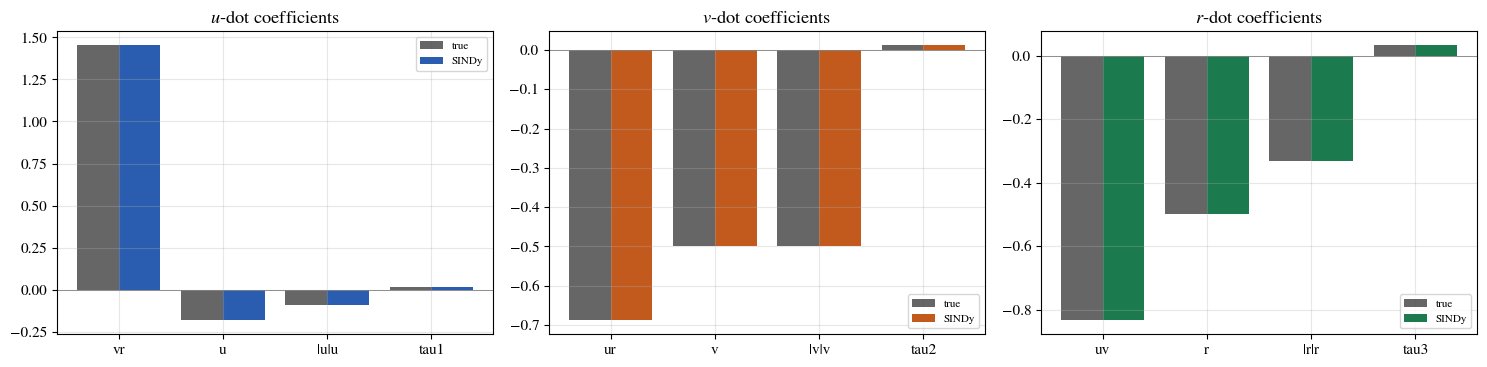

max coefficient error vs truth: 0.0


In [3]:
truth = {
    'udot': {'vr': 80/55, 'u': -10/55, '|u|u': -5/55, 'tau1': 1/55},
    'vdot': {'ur': -55/80, 'v': -40/80, '|v|v': -40/80, 'tau2': 1/80},
    'rdot': {'uv': -25/30, 'r': -15/30, '|r|r': -10/30, 'tau3': 1/30},
}
eqs = ['udot', 'vdot', 'rdot']

def plot_sindy_coeffs():
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for c, eq in enumerate(eqs):
        terms = list(truth[eq]); xpos = np.arange(len(terms))
        disc = [Xi[names.index(tm), c] for tm in terms]; tru = [truth[eq][tm] for tm in terms]
        ax[c].bar(xpos - 0.2, tru, 0.4, label='true', color=fg(), alpha=0.6)
        ax[c].bar(xpos + 0.2, disc, 0.4, label='SINDy', color=f'C{c}')
        ax[c].set_xticks(xpos); ax[c].set_xticklabels(terms); ax[c].axhline(0, color='gray', lw=0.6)
        ax[c].set(title=f'${eq[0]}$-dot coefficients'); ax[c].legend(fontsize=8)
    plt.tight_layout()

save_dual(plot_sindy_coeffs, 'sindy_coeffs', FIG)
plt.show()
maxerr = max(abs(Xi[names.index(tm), c] - truth[eq][tm]) for c, eq in enumerate(eqs) for tm in truth[eq])
print('max coefficient error vs truth:', round(maxerr, 4)); assert maxerr < 0.05

## 2. The sparsity knob: a threshold sweep

STLSQ has one hyperparameter, the threshold $\lambda$. Too small keeps spurious terms (under
noise); too large deletes real ones. Sweeping $\lambda$ on the benchmark shows a wide
*plateau* where the active-term count holds at the true total and the model error is at
machine zero --- then, once $\lambda$ exceeds the smallest real coefficient, true terms are pruned
and the error jumps off a cliff. Any $\lambda$ on the plateau recovers the exact model.

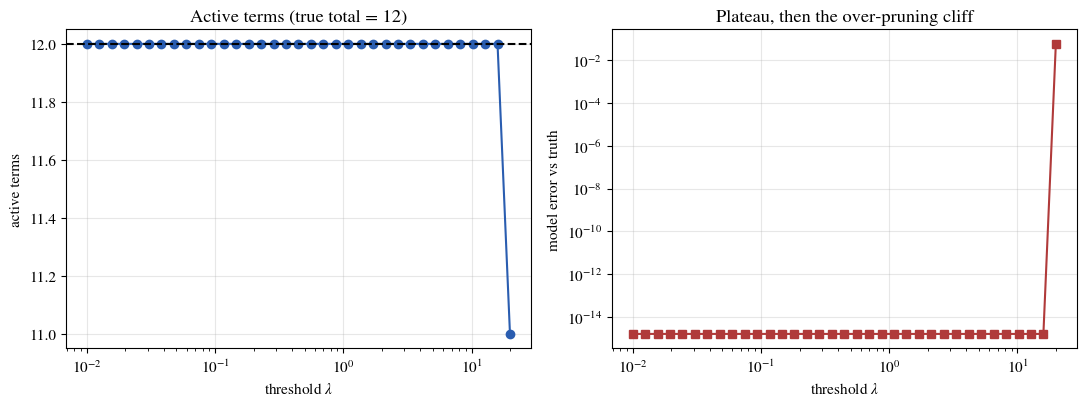

In [4]:
lams = np.logspace(-2, 1.3, 35); n_active, model_err = [], []
true_count = sum(len(truth[eq]) for eq in eqs)
for lam in lams:
    Xl = stlsq(Theta, nudot, lam=lam)
    n_active.append(int((np.abs(Xl) > 1e-9).sum()))
    model_err.append(np.linalg.norm(Theta @ Xl - nudot) / np.linalg.norm(nudot) + 1e-16)

def plot_sindy_pareto():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].semilogx(lams, n_active, 'o-', color='C0'); ax[0].axhline(true_count, ls='--', c='k')
    ax[0].set(xlabel=r'threshold $\lambda$', ylabel='active terms',
              title=f'Active terms (true total = {true_count})')
    ax[1].loglog(lams, model_err, 's-', color='C3')
    ax[1].set(xlabel=r'threshold $\lambda$', ylabel='model error vs truth',
              title='Plateau, then the over-pruning cliff')
    plt.tight_layout()

save_dual(plot_sindy_pareto, 'sindy_pareto', FIG)
plt.show()

## 3. Noise robustness and ensemble uncertainty

With noisy measurements a single fit is fragile. **Ensemble-SINDy** (bootstrap the data, refit
many times) turns a point estimate into a distribution: the true terms stand one to two orders of
magnitude above the spurious ones, and the bootstrap gives error bars on their values. (Estimating
the acceleration from noisy measurements by finite differences is a separate problem --- section 4 and
the weak form --- so here we add noise to the measured $(\boldsymbol\nu,\dot{\boldsymbol\nu})$
directly to isolate the sparse-regression robustness.)

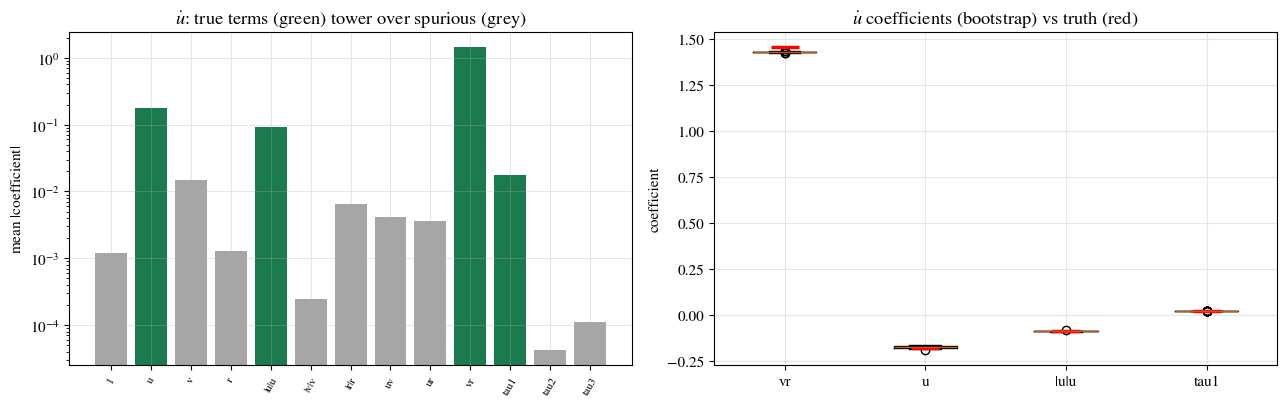

ensemble of B=80 STLSQ fits took 1.62 s
udot terms by magnitude: [('vr', np.float64(1.429)), ('u', np.float64(0.177)), ('|u|u', np.float64(0.091)), ('tau1', np.float64(0.018)), ('v', np.float64(0.015)), ('|r|r', np.float64(0.007))]


In [5]:
nu_n = nu + ENS_NOISE*nu.std(0)*np.random.randn(*nu.shape)
nd_n = nudot + ENS_NOISE*nudot.std(0)*np.random.randn(*nudot.shape)
Th_n, _ = library(nu_n, tau)
from time import perf_counter
B, m = ENS_B, len(t); coefs = []; t_ens = perf_counter()
for b in range(B):
    idx = np.random.choice(m, m, replace=True)
    coefs.append(stlsq(Th_n[idx], nd_n[idx], lam=ENS_LAM))
t_ens = perf_counter() - t_ens
coefs = np.array(coefs); cu = coefs[:, :, 0]               # u-dot column
magn = np.abs(cu.mean(0)); true_u = set(truth['udot'])
colors = ['C2' if nm in true_u else '0.65' for nm in names]

def plot_sindy_ensemble():
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    ax[0].bar(np.arange(len(names)), magn, color=colors)
    ax[0].set_yscale('log'); ax[0].set_xticks(np.arange(len(names)))
    ax[0].set_xticklabels(names, rotation=60, fontsize=8)
    ax[0].set(ylabel='mean $|$coefficient$|$', title=r'$\dot u$: true terms (green) tower over spurious (grey)')
    terms = list(truth['udot'])
    ax[1].boxplot([cu[:, names.index(tm)] for tm in terms], tick_labels=terms)
    for i, tm in enumerate(terms): ax[1].plot(i+1, truth['udot'][tm], 'r_', ms=20, mew=2.5)
    ax[1].set(ylabel='coefficient', title=r'$\dot u$ coefficients (bootstrap) vs truth (red)')
    plt.tight_layout()

save_dual(plot_sindy_ensemble, 'sindy_ensemble', FIG)
plt.show()
order = np.argsort(magn)[::-1]
print(f'ensemble of B={B} STLSQ fits took {t_ens:.2f} s')
print('udot terms by magnitude:', [(names[i], round(magn[i], 3)) for i in order[:6]])

## 4. The weak form: never differentiate the data

Sections 1--3 used analytic derivatives, which real data never offers. Estimating
$\dot{\boldsymbol\nu}$ by finite differences amplifies measurement noise by $1/\Delta t$. The
**weak (integral) form** removes derivatives of the data altogether: multiply
$\dot{\boldsymbol\nu}=\boldsymbol\Theta(\boldsymbol\nu,\boldsymbol\tau)\,\boldsymbol\Xi$ by a smooth
test function $\varphi_k(t)$ compactly supported on a window $[a_k,b_k]$ and integrate by parts
(the boundary term vanishes because $\varphi_k(a_k)=\varphi_k(b_k)=0$):

$$-\int_{a_k}^{b_k}\boldsymbol\nu\,\dot\varphi_k\,\mathrm{d}t
  \;=\;\Big[\int_{a_k}^{b_k}\boldsymbol\Theta(\boldsymbol\nu,\boldsymbol\tau)\,\varphi_k\,\mathrm{d}t\Big]\boldsymbol\Xi .$$

One row per window --- here 60 overlapping windows of 8 s, the bump $\varphi=((t-a)(b-t))^4$ and
trapezoidal quadrature --- gives a $60\times13$ system that the same STLSQ solves. The derivative now
acts on the *known* $\varphi_k$; the data only ever enter integrals, which average noise down instead
of amplifying it.

**Noise sweep.** Gaussian noise is added to $\boldsymbol\nu$ at $\{0,0.5,1,2,5,10\}\%$ of each
channel's standard deviation; plain STLSQ on `np.gradient` derivatives is compared with the weak form.
Both use the same threshold $\lambda=1$, which lies inside both methods' clean-data plateaus (printed
below). Metrics: the maximum relative error over the twelve true coefficients and the number of wrong
terms (spurious kept + true deleted, out of 39 entries), median over 5 noise seeds.


clean plateau upper edge:  finite-difference 17.8,  weak form 2.0;  using lambda = 1.0
clean data, max relative coefficient error:  FD 7.2e-04,  weak 5.4e-08


time per fit:  finite-difference STLSQ 0.011 s,  weak-form build + STLSQ 0.003 s
 noise | FD max rel err  wrong | weak max rel err  wrong   (medians over 5 seeds)
    0% |       7.19e-04      0 |         5.35e-08      0
  0.5% |       5.45e-03      0 |         5.44e-03      0
    1% |       1.12e-02      0 |         1.08e-02      0
    2% |       5.38e-02      7 |         2.15e-02      0
    5% |       3.44e-01     20 |         5.20e-02      0
   10% |       6.63e-01     25 |         9.89e-02      0


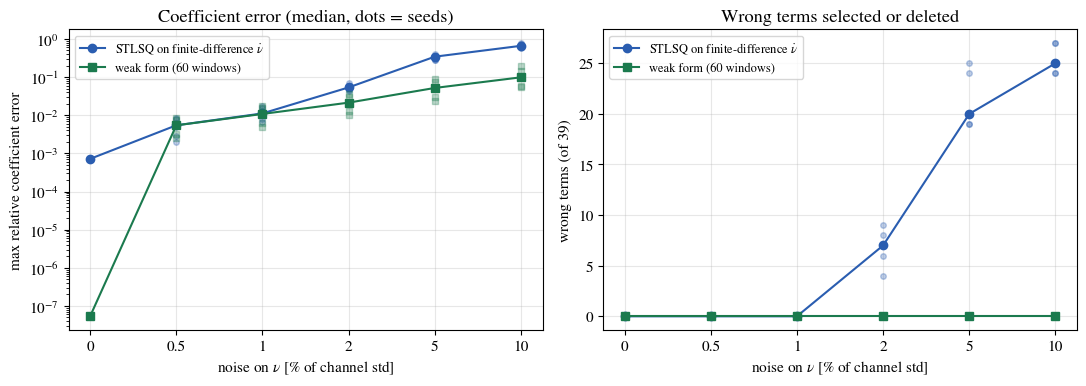

In [6]:
from time import perf_counter
trapz = getattr(np, 'trapezoid', None) or np.trapz      # numpy 2.x / 1.x

def weak_system(nu, tau, t, n_windows=N_WIN, width=WIN_LEN, q=WIN_Q):
    # rows: test functions phi_k on windows of `width` samples; b_k = -int nu phi_k' dt, G_kj = int theta_j phi_k dt
    Th, _ = library(nu, tau); m = len(t)
    starts = np.linspace(0, m - width, n_windows).astype(int)
    G = np.empty((n_windows, Th.shape[1])); b = np.empty((n_windows, nu.shape[1]))
    for k, s in enumerate(starts):
        sl = slice(s, s + width); tk = t[sl]; a, bb = tk[0], tk[-1]
        phi = ((tk - a)*(bb - tk))**q                                 # compactly supported bump
        dphi = q*((tk - a)*(bb - tk))**(q - 1)*((bb - tk) - (tk - a))  # its analytic derivative
        scale = trapz(phi, tk); phi, dphi = phi/scale, dphi/scale
        b[k] = -trapz(dphi[:, None]*nu[sl], tk, axis=0)
        G[k] = trapz(phi[:, None]*Th[sl], tk, axis=0)
    return G, b

Xi_true = np.zeros_like(Xi)
for c, eq in enumerate(eqs):
    for tm, val in truth[eq].items(): Xi_true[names.index(tm), c] = val
active = Xi_true != 0

def score(Xi_hat):
    rel = np.abs(Xi_hat[active] - Xi_true[active])/np.abs(Xi_true[active])
    wrong = int(((np.abs(Xi_hat) > 1e-9) != active).sum())
    return rel.max(), wrong

# clean-data plateaus of the two systems (largest lambda that still returns the exact support)
lam_grid = np.logspace(-2, 2, 81)
G0, b0 = weak_system(nu, tau, t); nd_fd0 = np.gradient(nu, dt, axis=0)
top_fd = max(l for l in lam_grid if score(stlsq(Theta, nd_fd0, l))[1] == 0)
top_wk = max(l for l in lam_grid if score(stlsq(G0, b0, l))[1] == 0)
LAM = LAM_WEAK
print(f'clean plateau upper edge:  finite-difference {top_fd:.1f},  weak form {top_wk:.1f};  using lambda = {LAM}')
print(f'clean data, max relative coefficient error:  FD {score(stlsq(Theta, nd_fd0, LAM))[0]:.1e},  weak {score(stlsq(G0, b0, LAM))[0]:.1e}')

levels = NOISE_LEVELS; seeds = range(N_SEEDS)
err_fd = np.empty((len(levels), len(seeds))); err_wk = np.empty_like(err_fd)
wrong_fd = np.empty_like(err_fd); wrong_wk = np.empty_like(err_fd); t_fd = t_wk = 0.0
for i, lev in enumerate(levels):
    for s in seeds:
        rng = np.random.default_rng(s)
        nu_s = nu + lev/100*nu.std(0)*rng.standard_normal(nu.shape)
        Th_s, _ = library(nu_s, tau)
        t0 = perf_counter(); Xi_fd = stlsq(Th_s, np.gradient(nu_s, dt, axis=0), LAM); t_fd += perf_counter() - t0
        t0 = perf_counter(); G, bv = weak_system(nu_s, tau, t); Xi_wk = stlsq(G, bv, LAM); t_wk += perf_counter() - t0
        err_fd[i, s], wrong_fd[i, s] = score(Xi_fd); err_wk[i, s], wrong_wk[i, s] = score(Xi_wk)
n_fits = len(levels)*len(seeds)
print(f'time per fit:  finite-difference STLSQ {t_fd/n_fits:.3f} s,  weak-form build + STLSQ {t_wk/n_fits:.3f} s')
print(f'{"noise":>6} | {"FD max rel err":>14} {"wrong":>6} | {"weak max rel err":>16} {"wrong":>6}   (medians over 5 seeds)')
for i, lev in enumerate(levels):
    print(f'{lev:5}% | {np.median(err_fd[i]):14.2e} {np.median(wrong_fd[i]):6.0f} | {np.median(err_wk[i]):16.2e} {np.median(wrong_wk[i]):6.0f}')

def plot_ed_weakform_noise():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.0)); x = np.arange(len(levels))
    for a in ax: a.set_xticks(x); a.set_xticklabels([str(l) for l in levels]); a.set_xlabel('noise on $\\nu$ [% of channel std]')
    for e, w, lab, col, mk in [(err_fd, wrong_fd, 'STLSQ on finite-difference $\\dot\\nu$', 'C0', 'o'),
                               (err_wk, wrong_wk, 'weak form (60 windows)', 'C2', 's')]:
        ax[0].semilogy(x, np.median(e, 1), mk + '-', color=col, label=lab)
        for s in seeds: ax[0].semilogy(x, e[:, s], mk, color=col, alpha=0.3, ms=4)
        ax[1].plot(x, np.median(w, 1), mk + '-', color=col, label=lab)
        for s in seeds: ax[1].plot(x, w[:, s], mk, color=col, alpha=0.3, ms=4)
    ax[0].set(ylabel='max relative coefficient error', title='Coefficient error (median, dots = seeds)'); ax[0].legend(fontsize=9)
    ax[1].set(ylabel='wrong terms (of 39)', title='Wrong terms selected or deleted'); ax[1].legend(fontsize=9)
    plt.tight_layout()

save_dual(plot_ed_weakform_noise, 'ed_weakform_noise', FIG)
plt.show()


## 5. Validation on an unseen maneuver

The strict test is not the regression $R^2$ but whether the discovered *equations* reproduce
dynamics they were not fit on. We integrate the discovered model on a **turning circle** (never
used for identification) and compare to the benchmark.

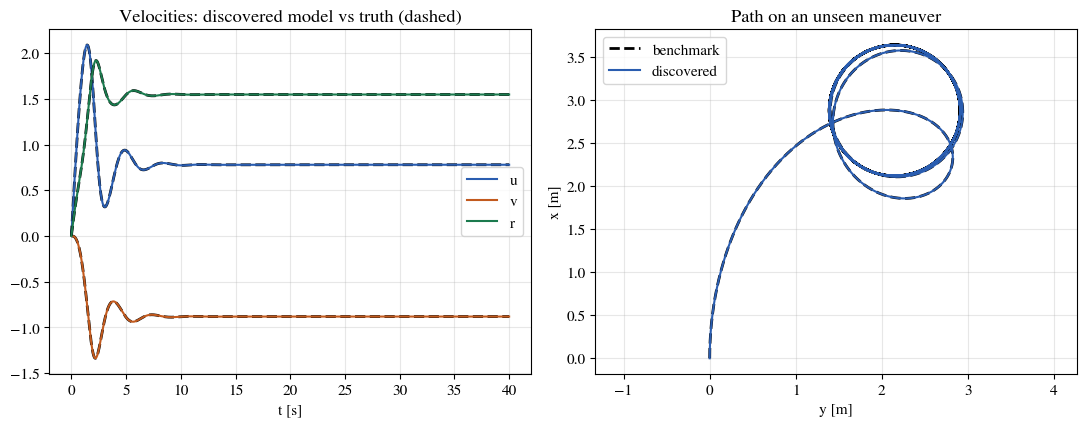

path final error: 0.0


In [7]:
def discovered_deriv(z, tau):
    nuk = z[3:]; Th1, _ = library(nuk[None, :], np.asarray(tau)[None, :])
    return np.concatenate([vessel.rotation(z[2]) @ nuk, (Th1 @ Xi)[0]])

def rk4(deriv, z0, tfn, t_end=40.0, dt=0.02):
    n = int(round(t_end/dt)); tt = np.linspace(0, n*dt, n+1); Zo = np.empty((n+1, 6)); z = z0.copy(); Zo[0] = z
    for k in range(n):
        tk = tt[k]; ta = tfn(tk, z)
        k1 = deriv(z, ta); k2 = deriv(z+0.5*dt*k1, ta); k3 = deriv(z+0.5*dt*k2, ta); k4 = deriv(z+dt*k3, ta)
        z = z + dt/6*(k1+2*k2+2*k3+k4); Zo[k+1] = z
    return tt, Zo

tc_fn = vessel.turning_circle(VAL_TAU1, VAL_TAU3); z0 = np.zeros(6)
tt, Z_disc = rk4(discovered_deriv, z0, tc_fn, t_end=VAL_T, dt=DT)
_, Z_true = vessel.simulate(tc_fn, t_end=VAL_T, dt=DT, p=p)

def plot_sindy_validation():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
    for j, lab in enumerate(['u', 'v', 'r']):
        ax[0].plot(tt, Z_true[:, 3+j], '--', color=fg(), lw=2); ax[0].plot(tt, Z_disc[:, 3+j], color=f'C{j}', label=lab)
    ax[0].set(xlabel='t [s]', title='Velocities: discovered model vs truth (dashed)'); ax[0].legend()
    ax[1].plot(Z_true[:, 1], Z_true[:, 0], '--', color=fg(), lw=2, label='benchmark'); ax[1].plot(Z_disc[:, 1], Z_disc[:, 0], 'C0', label='discovered')
    ax[1].axis('equal'); ax[1].legend(); ax[1].set(xlabel='y [m]', ylabel='x [m]', title='Path on an unseen maneuver')
    plt.tight_layout()

save_dual(plot_sindy_validation, 'sindy_validation', FIG)
plt.show()
print('path final error:', round(float(np.linalg.norm(Z_disc[-1, :3]-Z_true[-1, :3])), 4))

## 6. Closing the loop: SINDy on a learned correction

Suppose the physics model omits the quadratic drag, and a hybrid model has learned the missing force as a
neural-network correction $\boldsymbol{f}_{\boldsymbol\theta}(\boldsymbol\nu)\approx\boldsymbol{d}(\boldsymbol\nu)$ added
to the equations (a *corrective source term*) --- a black box that makes the simulation right.
Sampling that force over the states the vessel visited and running sparse regression on it recovers
the missing drag as an **explicit equation** --- here the true
$\boldsymbol{d}=(-3u|u|,\,-8v|v|,\,-2r|r|)$ --- turning a learned correction back into interpretable
physics.

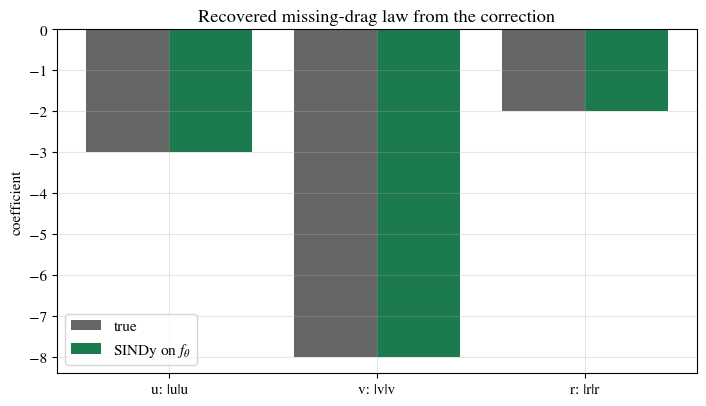

discovered drag:  u: |u|u = -3.00,  v: |v|v = -8.00,  r: |r|r = -2.00


In [8]:
def disturbance(nuk):
    u, v, r = nuk
    return np.array([-3.0*u*abs(u), -8.0*v*abs(v), -2.0*r*abs(r)])
D = np.array([disturbance(nuk) for nuk in nu])           # the CoSTA-learned force, sampled
Xi_d = stlsq(Theta, D, lam=LAM_LOOP)
drag_truth = {'udot': {'|u|u': -3.0}, 'vdot': {'|v|v': -8.0}, 'rdot': {'|r|r': -2.0}}

labels, disc, tru = [], [], []
for c, eq in enumerate(eqs):
    for tm, val in drag_truth[eq].items():
        labels.append(f'{eq[0]}: {tm}'); disc.append(Xi_d[names.index(tm), c]); tru.append(val)

def plot_sindy_loopclose():
    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    x = np.arange(len(labels))
    ax.bar(x-0.2, tru, 0.4, label='true', color=fg(), alpha=0.6); ax.bar(x+0.2, disc, 0.4, label='SINDy on $f_\\theta$', color='C2')
    ax.set_xticks(x); ax.set_xticklabels(labels); ax.axhline(0, color='gray', lw=0.6)
    ax.set(ylabel='coefficient', title='Recovered missing-drag law from the correction'); ax.legend()
    plt.tight_layout()

save_dual(plot_sindy_loopclose, 'sindy_loopclose', FIG)
plt.show()
print('discovered drag:  ' + ',  '.join(f'{l} = {d:+.2f}' for l, d in zip(labels, disc)))

## 7. STLSQ, step by step

What the solver actually does, on the $\dot u$ equation with $2\%$ noise on $\boldsymbol\nu$ and `np.gradient`
derivatives, threshold $\lambda=0.5$ on the normalized coefficients. Each panel is one pass: least squares on the
surviving columns, then every normalized coefficient below the threshold is deleted. The true terms are coloured,
spurious ones grey; deleted terms are drawn as empty outlines in the panel that deletes them.

active terms per pass: [13, 7, 4] -> final: ['u', '|u|u', 'vr', 'tau1']
final coefficients: {'u': -0.1857, '|u|u': -0.0886, 'vr': 1.4457, 'tau1': 0.0181}


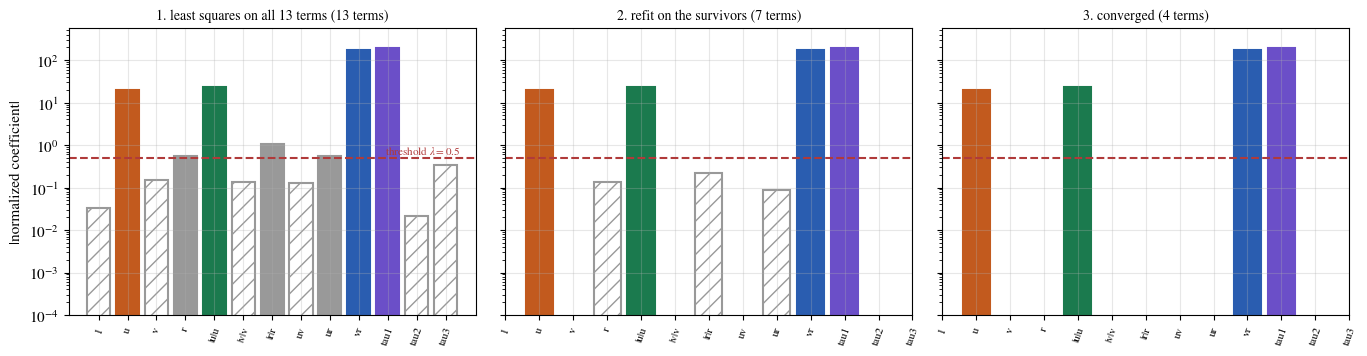

In [9]:
rng7 = np.random.default_rng(0)
nu7 = nu + STEP_NOISE*nu.std(0)*rng7.standard_normal(nu.shape); Th7, _ = library(nu7, tau); y7 = np.gradient(nu7, dt, axis=0)[:, 0]
LAM7 = STEP_LAM
norm7 = np.linalg.norm(Th7, axis=0); Tn7 = Th7/norm7
steps = []; xi = np.linalg.lstsq(Tn7, y7, rcond=None)[0]; alive = np.ones(len(names), bool)
while True:
    steps.append((xi.copy(), alive.copy()))
    keep = alive & (np.abs(xi) >= LAM7)
    if (keep == alive).all(): break
    alive = keep; xi = np.zeros_like(xi); xi[alive] = np.linalg.lstsq(Tn7[:, alive], y7, rcond=None)[0]
print('active terms per pass:', [int(a.sum()) for _, a in steps], '-> final:', [n for n, a in zip(names, steps[-1][1]) if a])
final7 = steps[-1][0]/norm7
print('final coefficients:', {n: round(float(v), 4) for n, v in zip(names, final7) if v != 0})
TERM_COL = {'vr': 'C0', 'u': 'C1', '|u|u': 'C2', 'tau1': 'C4'}

def plot_stlsq_steps():
    fig, ax = plt.subplots(1, len(steps), figsize=(4.6*len(steps), 3.7), sharey=True)
    xs = np.arange(len(names))
    for k, (a, (xk, al)) in enumerate(zip(np.atleast_1d(ax), steps)):
        mag = np.abs(xk)
        for j, n in enumerate(names):
            if not al[j]: continue
            col = TERM_COL.get(n, '0.6'); cut = mag[j] < LAM7 and k < len(steps) - 1
            a.bar(j, max(mag[j], 1e-4), color='none' if cut else col, edgecolor=col, lw=1.5, hatch='//' if cut else None)
        a.axhline(LAM7, color='C3', ls='--', lw=1.5); a.set_yscale('log'); a.set_ylim(1e-4, 3*max(np.abs(s[0]).max() for s in steps))
        a.set_xticks(xs); a.set_xticklabels(names, rotation=70, fontsize=8)
        ttl = ['least squares on all 13 terms', 'refit on the survivors', 'converged'][min(k, 2)] if len(steps) == 3 else f'pass {k}'
        a.set_title(f'{k + 1}. {ttl} ({int(al.sum())} terms)', fontsize=10)
        if k == 0:
            a.set_ylabel('|normalized coefficient|'); a.text(len(names) - 0.5, LAM7*1.25, f'threshold $\\lambda={LAM7:g}$',
                                                          color='C3', ha='right', fontsize=8)
    plt.tight_layout()

save_dual(plot_stlsq_steps, 'sindy_stlsq_steps', FIG)
plt.show()

## 8. The weak form, pictured

Three panels for the lecture. (a) Why finite differences fail: the derivative of the surge speed with $2\%$ noise,
by `np.gradient`, against the true $\dot u$. (b) The test functions: smooth bumps $\varphi_k(t)$, each zero outside
its $8$~s window, tiling the record (every tenth of the $60$ windows drawn). (c) One window: the noisy samples $u(t)$,
the bump $\varphi$ and its known derivative $\dot\varphi$. The weak form needs only $\int u\,\dot\varphi\,\mathrm dt$ and
$\int\theta_j(u)\,\varphi\,\mathrm dt$: weighted *averages* of the noisy samples, never their differences.

2 % noise on u: finite-difference u_dot has relative RMS error 0.78 (noise amplified by 1/dt)


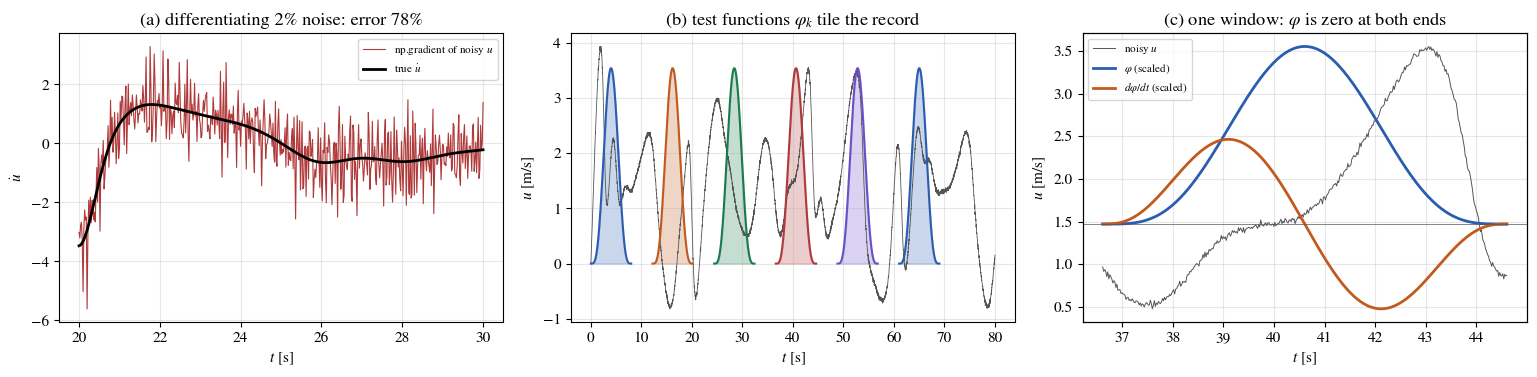

In [10]:
from pyutils import muted
rng8 = np.random.default_rng(0)
nu8 = nu + 0.02*nu.std(0)*rng8.standard_normal(nu.shape)
u8, ud_fd = nu8[:, 0], np.gradient(nu8[:, 0], dt)
width8, nwin8, q8 = WIN_LEN, N_WIN, WIN_Q
starts8 = np.linspace(0, len(t) - width8, nwin8).astype(int)
def bump8(s):
    tk = t[s:s + width8]; a, b = tk[0], tk[-1]
    phi = ((tk - a)*(b - tk))**q8; dphi = q8*((tk - a)*(b - tk))**(q8 - 1)*((b - tk) - (tk - a))
    sc = trapz(phi, tk); return tk, phi/sc, dphi/sc
err_fd8 = np.sqrt(np.mean((ud_fd - nudot[:, 0])**2))/nudot[:, 0].std()
print(f'2 % noise on u: finite-difference u_dot has relative RMS error {err_fd8:.2f} (noise amplified by 1/dt)')

def plot_weakform_idea():
    fig, ax = plt.subplots(1, 3, figsize=(15.5, 3.9))
    sl = (t >= 20) & (t <= 30)
    ax[0].plot(t[sl], ud_fd[sl], color='C3', lw=0.8, label='np.gradient of noisy $u$')
    ax[0].plot(t[sl], nudot[sl, 0], color=fg(), lw=2, label='true $\\dot u$')
    ax[0].set(xlabel='$t$ [s]', ylabel='$\\dot u$', title=f'(a) differentiating 2% noise: error {err_fd8*100:.0f}%')
    ax[0].legend(fontsize=8, loc='upper right')
    ax[1].plot(t, u8, color=muted(), lw=0.6, label='noisy $u(t)$')
    ymax = u8.max()
    for k, s in enumerate(starts8[::10]):
        tk, phi, _ = bump8(s); col = f'C{k % 5}'
        ax[1].fill_between(tk, 0, phi/phi.max()*0.9*ymax, color=col, alpha=0.25)
        ax[1].plot(tk, phi/phi.max()*0.9*ymax, color=col, lw=1.5)
    ax[1].set(xlabel='$t$ [s]', ylabel='$u$ [m/s]', title='(b) test functions $\\varphi_k$ tile the record')
    s = starts8[30]; tk, phi, dphi = bump8(s); seg = u8[s:s + width8]
    a2 = ax[2]; a2.plot(tk, seg, color=muted(), lw=0.7, label='noisy $u$')
    a2.set(xlabel='$t$ [s]', ylabel='$u$ [m/s]', title='(c) one window: $\\varphi$ is zero at both ends')
    b2 = a2.twinx()
    b2.plot(tk, phi/np.abs(dphi).max(), color='C0', lw=2, label='$\\varphi$ (scaled)')
    b2.plot(tk, dphi/np.abs(dphi).max(), color='C1', lw=2, label='$d\\varphi/dt$ (scaled)')
    b2.axhline(0, color=muted(), lw=0.5); b2.set_yticks([])
    h1, l1 = a2.get_legend_handles_labels(); h2, l2 = b2.get_legend_handles_labels()
    a2.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper left')
    plt.tight_layout()

save_dual(plot_weakform_idea, 'ed_weakform_idea', FIG)
plt.show()

## 9. The derivative error budget, checked

The central difference of noisy samples $y_k=x(t_k)+\varepsilon_k$ makes two errors: truncation
$\tfrac{\Delta t^2}{6}\dddot x$ (shrinks with $\Delta t$) and noise $(\varepsilon_{k+1}-\varepsilon_{k-1})/2\Delta t$ of size
$s/(\sqrt2\,\Delta t)$ (grows). Their sum $E(\Delta t)\approx\tfrac{\Delta t^2}{6}M_3+\tfrac{s}{\sqrt2\,\Delta t}$ has a best step
$\Delta t^\ast=(3s/\sqrt2M_3)^{1/3}$. The check: differentiate $x=\sin t$ ($M_3=\max|\dddot x|=1$) sampled with noise
$s=10^{-3}$ at many steps, and compare the measured RMS error with the formula. (For the comparison both error terms are
RMS values: the truncation term averages $|\dddot x|=|\cos t|$ to $1/\sqrt2$.)

optimal step dt* = 0.128; formula error there 0.0061; measured at dt = 1e-3: 0.705 (formula 0.707)


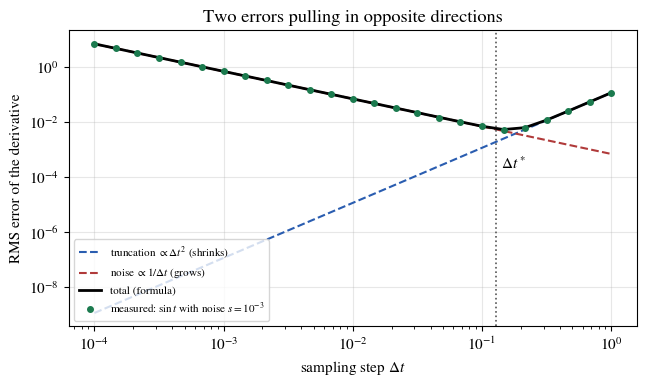

In [11]:
s9, M3 = 1e-3, 1.0
dts = np.logspace(-4, 0, 25)
rng9 = np.random.default_rng(0)
meas = []
for h in dts:
    tt = np.arange(0, 200, h)[:400000]
    y = np.sin(tt) + s9*rng9.standard_normal(len(tt))
    d = (y[2:] - y[:-2])/(2*h)
    meas.append(np.sqrt(np.mean((d - np.cos(tt[1:-1]))**2)))
meas = np.array(meas)
trunc = dts**2/6*M3/np.sqrt(2); noise = s9/(np.sqrt(2)*dts); total = np.sqrt(trunc**2 + noise**2)
dt_star = (3*s9/(np.sqrt(2)*M3))**(1/3)
print(f'optimal step dt* = {dt_star:.3f}; formula error there {np.interp(dt_star, dts, total):.4f}; '
      f'measured at dt = 1e-3: {np.interp(1e-3, dts, meas):.3f} (formula {s9/(np.sqrt(2)*1e-3):.3f})')

def plot_diff_budget():
    fig, ax = plt.subplots(figsize=(6.6, 4.0))
    ax.loglog(dts, trunc, '--', color='C0', label='truncation $\\propto\\Delta t^2$ (shrinks)')
    ax.loglog(dts, noise, '--', color='C3', label='noise $\\propto 1/\\Delta t$ (grows)')
    ax.loglog(dts, total, color=fg(), lw=2, label='total (formula)')
    ax.loglog(dts, meas, 'o', color='C2', ms=4, label='measured: $\\sin t$ with noise $s=10^{-3}$')
    ax.axvline(dt_star, color=muted(), ls=':', lw=1.2); ax.text(dt_star*1.1, 2e-4, '$\\Delta t^*$', color=fg())
    ax.set(xlabel='sampling step $\\Delta t$', ylabel='RMS error of the derivative', title='Two errors pulling in opposite directions')
    ax.legend(fontsize=8, loc='lower left'); plt.tight_layout()

save_dual(plot_diff_budget, 'ed_diff_budget', FIG)
plt.show()

**Takeaways.** SINDy recovers the maneuvering model and its coefficients from data, with a
single interpretable knob (the threshold) chosen from the sparsity plateau, and ensembling supplies
uncertainty under noise. The discovered equations *generalize* --- they reproduce an unseen
maneuver --- because they are the real physics, not a fit. And running SINDy on a learned correction
recovers missing terms symbolically, completing the data $\to$ black box $\to$ correction $\to$
equation arc. The weak form removes derivative estimation from the
pipeline: on this benchmark it identifies the correct twelve terms up to 10% measurement noise,
where finite-difference SINDy has already failed at 2%; production tools (`PySINDy`) ship it.